In [ ]:
from pathlib import Path
import re
import pandas as pd

import kagglehub

DATASET_HANDLE = 'jacksoncrow/stock-market-dataset'
ASSET_CLASSES = ['stocks', 'etfs']  # use either or both
SYMBOLS = None  # None processes every symbol; or use ['AAPL', 'SPY']
OUTPUT_DIR = Path.cwd() / 'processed_data'
PRICE_COLUMNS = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

DATASET_DIR = Path(kagglehub.dataset_download(DATASET_HANDLE))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

missing_folders = [name for name in ASSET_CLASSES if not (DATASET_DIR / name).is_dir()]
if missing_folders:
    raise FileNotFoundError(f'Expected dataset folders not found: {missing_folders}')

print(f'Dataset source: {DATASET_HANDLE}')
print(f'Downloaded files: {DATASET_DIR}')
print(f'Output folder: {OUTPUT_DIR.resolve()}')


## 2. Inspect the downloaded files

The dataset contains one daily price CSV per symbol in the stocks and ETFs folders, plus a symbol metadata table. Choose asset classes or symbols in the configuration cell above; by default all available stock and ETF files are included.


In [ ]:
price_files = []
for asset_class in ASSET_CLASSES:
    price_files.extend(sorted((DATASET_DIR / asset_class).glob('*.csv')))

available_symbols = {(file.parent.name, file.stem.upper()) for file in price_files}
if SYMBOLS is not None:
    requested_symbols = {str(symbol).strip().upper() for symbol in SYMBOLS}
    selected_files = [p for p in price_files if p.stem.upper() in requested_symbols]
    found_symbols = {p.stem.upper() for p in selected_files}
    missing_symbols = sorted(requested_symbols - found_symbols)
    if missing_symbols:
        print('Symbols not found in selected asset folders:', missing_symbols)
    price_files = selected_files

print(f'Files selected: {len(price_files):,}')
print('Sample paths:', [str(p.relative_to(DATASET_DIR)) for p in price_files[:10]])

metadata_path = DATASET_DIR / 'symbols_valid_meta.csv'
if metadata_path.exists():
    symbol_metadata = pd.read_csv(metadata_path)
    display(symbol_metadata.head())
    print(f'Metadata rows: {len(symbol_metadata):,}; columns: {list(symbol_metadata.columns)}')


## 3. Define light, reusable preprocessing

The function keeps every price row with a valid date, preserves missing numeric values, and records any values that could not be parsed as numbers. Duplicate rows are identified by asset class, symbol, and date; the last source row is retained.


In [ ]:
def clean_price_frame(frame, symbol, asset_class):
    frame = frame.copy()
    frame.columns = [str(column).strip() for column in frame.columns]

    if 'Date' not in frame.columns:
        raise ValueError(f'{symbol}: required Date column is missing')

    missing_columns = [column for column in PRICE_COLUMNS if column not in frame.columns]
    for column in missing_columns:
        frame[column] = pd.NA

    rows_in = len(frame)
    frame['Date'] = pd.to_datetime(frame['Date'], errors='coerce')
    invalid_dates = int(frame['Date'].isna().sum())
    frame = frame.dropna(subset=['Date'])

    invalid_numeric_values = 0
    for column in PRICE_COLUMNS:
        raw = frame[column]
        has_source_value = raw.notna() & raw.astype('string').str.strip().ne('')
        frame[column] = pd.to_numeric(raw, errors='coerce')
        invalid_numeric_values += int((has_source_value & frame[column].isna()).sum())

    frame['Symbol'] = symbol.upper()
    frame['AssetClass'] = asset_class.lower()
    duplicate_rows = int(frame.duplicated(
        subset=['AssetClass', 'Symbol', 'Date'], keep='last'
    ).sum())
    frame = frame.drop_duplicates(
        subset=['AssetClass', 'Symbol', 'Date'], keep='last'
    ).sort_values('Date').reset_index(drop=True)

    frame = frame[['Date', 'Symbol', 'AssetClass', *PRICE_COLUMNS]]
    missing_by_column = frame[PRICE_COLUMNS].isna().sum().to_dict()

    report = {
        'AssetClass': asset_class.lower(),
        'Symbol': symbol.upper(),
        'rows_in': rows_in,
        'invalid_dates_dropped': invalid_dates,
        'duplicate_rows_dropped': duplicate_rows,
        'invalid_numeric_values': invalid_numeric_values,
        'rows_out': len(frame),
        'missing_price_values': int(frame[PRICE_COLUMNS].isna().sum().sum()),
        'missing_columns_added': ','.join(missing_columns),
        'date_min': frame['Date'].min() if not frame.empty else pd.NaT,
        'date_max': frame['Date'].max() if not frame.empty else pd.NaT,
        **{f'missing_{column}': int(count) for column, count in missing_by_column.items()},
    }
    return frame, report


def safe_filename(symbol):
    return re.sub(r'[^A-Za-z0-9._-]+', '_', symbol.upper())


## 4. Process selected symbols

Each symbol is saved separately as Parquet. This keeps memory use manageable, makes it easy to work with individual instruments, and allows DuckDB to query many files together. Source CSVs remain in the KaggleHub download cache and are not modified.


In [ ]:
quality_rows = []
processed_files = []

for index, file_path in enumerate(price_files, start=1):
    symbol = file_path.stem.upper()
    asset_class = file_path.parent.name.lower()

    raw = pd.read_csv(file_path)
    cleaned, report = clean_price_frame(raw, symbol, asset_class)

    class_output = OUTPUT_DIR / asset_class
    class_output.mkdir(parents=True, exist_ok=True)
    destination = class_output / f'{safe_filename(symbol)}.parquet'
    cleaned.to_parquet(destination, index=False)

    quality_rows.append(report)
    processed_files.append(destination)

    if index % 250 == 0 or index == len(price_files):
        print(f'Processed {index:,} of {len(price_files):,} files')

if not quality_rows:
    raise RuntimeError('No price files were processed. Check ASSET_CLASSES and SYMBOLS.')

quality_report = pd.DataFrame(quality_rows)
report_path = OUTPUT_DIR / 'preprocessing_report.csv'
quality_report.to_csv(report_path, index=False)

print(f'Processed {len(processed_files):,} symbol files.')
print(f'Quality report: {report_path.resolve()}')
display(quality_report.head())


## 5. Review preprocessing quality


In [ ]:
print('Rows kept by asset class:')
display(quality_report.groupby('AssetClass')[['rows_in', 'rows_out']].sum())

print('Issues to review:')
display(quality_report[
    (quality_report['invalid_dates_dropped'] > 0)
    | (quality_report['duplicate_rows_dropped'] > 0)
    | (quality_report['invalid_numeric_values'] > 0)
    | (quality_report['missing_price_values'] > 0)
].head(20))

print('Cleaned date ranges:')
display(quality_report.groupby('AssetClass').agg(
    symbols=('Symbol', 'nunique'),
    earliest_date=('date_min', 'min'),
    latest_date=('date_max', 'max'),
    rows=('rows_out', 'sum'),
))


## 6. Visualize coverage and preprocessing checks

These charts summarize the processed files, missing price values, and rows affected by basic cleanup. The top-symbol chart is capped to keep it readable. They are diagnostics, not filters.


In [ ]:
import matplotlib.pyplot as plt

rows_by_class = quality_report.groupby('AssetClass')['rows_out'].sum().sort_values(ascending=False)
total_rows = max(int(quality_report['rows_out'].sum()), 1)
missing_columns = [column for column in quality_report.columns if column.startswith('missing_')]
missing_pct = pd.Series({
    column.removeprefix('missing_'): quality_report[column].sum() / total_rows * 100
    for column in missing_columns
}).sort_values(ascending=False)
top_symbols = quality_report.nlargest(20, 'rows_out').copy()
top_symbols['Label'] = top_symbols['Symbol'] + ' (' + top_symbols['AssetClass'] + ')'
cleanup_counts = quality_report.groupby('AssetClass')[
    ['invalid_dates_dropped', 'duplicate_rows_dropped', 'invalid_numeric_values']
].sum()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
rows_by_class.plot(kind='bar', ax=axes[0, 0], color='#4472C4')
axes[0, 0].set(title='Cleaned observations by asset class', xlabel='', ylabel='Rows')
axes[0, 0].tick_params(axis='x', rotation=0)

missing_pct.plot(kind='bar', ax=axes[0, 1], color='#ED7D31')
axes[0, 1].set(title='Missing price values across cleaned rows', xlabel='', ylabel='Percent of rows')
axes[0, 1].tick_params(axis='x', rotation=30)

top_symbols.sort_values('rows_out').plot(
    x='Label', y='rows_out', kind='barh', ax=axes[1, 0], legend=False, color='#70AD47'
)
axes[1, 0].set(title='Symbols with the most observations (top 20)', xlabel='Rows', ylabel='')

cleanup_counts.plot(kind='bar', ax=axes[1, 1], color=['#5B9BD5', '#A5A5A5', '#FFC000'])
axes[1, 1].set(title='Rows flagged during cleanup', xlabel='', ylabel='Rows')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].legend(['Invalid dates dropped', 'Duplicate rows dropped', 'Invalid numeric values'])
fig.tight_layout()
plt.show()


## 6. Query the cleaned data without choosing an analysis

DuckDB can query the per-symbol Parquet files together. This creates a view named prices and shows a small sample. Use the view for your own questions, filters, joins, visualizations, feature engineering, or modeling.


In [ ]:
import duckdb

parquet_globs = [
    (OUTPUT_DIR / asset_class / '*.parquet').resolve().as_posix()
    for asset_class in ASSET_CLASSES
    if list((OUTPUT_DIR / asset_class).glob('*.parquet'))
]
if not parquet_globs:
    raise FileNotFoundError('No cleaned Parquet files found in the output folder.')

glob_sql = ', '.join("'" + path.replace("'", "''") + "'" for path in parquet_globs)
db = duckdb.connect(database=':memory:')
db.execute(
    f"CREATE VIEW prices AS SELECT * FROM read_parquet([{glob_sql}], union_by_name=true)"
)

print('Available columns:')
display(db.execute('DESCRIBE prices').df())
print('Sample rows:')
display(db.execute('SELECT * FROM prices LIMIT 10').df())


## 8. Visualize one example series

Choose a symbol and optional asset class below. Leaving the symbol as None selects the symbol with the most cleaned observations. The chart shows adjusted close when available, plus a daily-return diagnostic; the return series is only a temporary view and is not added to the prepared dataset.


In [ ]:
VISUALIZATION_SYMBOL = None  # e.g. 'AAPL'
VISUALIZATION_ASSET_CLASS = None  # e.g. 'stocks' or 'etfs'

if VISUALIZATION_SYMBOL is None:
    chosen = quality_report.sort_values('rows_out').iloc[-1]
else:
    candidates = quality_report[
        quality_report['Symbol'].eq(str(VISUALIZATION_SYMBOL).upper())
    ]
    if VISUALIZATION_ASSET_CLASS is not None:
        candidates = candidates[candidates['AssetClass'].eq(VISUALIZATION_ASSET_CLASS.lower())]
    if candidates.empty:
        raise ValueError('The requested symbol was not processed. Check SYMBOLS and ASSET_CLASSES.')
    chosen = candidates.sort_values('rows_out').iloc[-1]

sample_symbol = chosen['Symbol']
sample_asset_class = chosen['AssetClass']
sample_prices = db.execute(
    'SELECT Date, "Adj Close", Close FROM prices '
    'WHERE Symbol = ? AND AssetClass = ? ORDER BY Date',
    [sample_symbol, sample_asset_class],
).df()

if sample_prices.empty:
    raise RuntimeError('No price rows found for the selected visualization symbol.')

sample_prices['Date'] = pd.to_datetime(sample_prices['Date'])
price_column = 'Adj Close' if sample_prices['Adj Close'].notna().any() else 'Close'
sample_prices[price_column] = pd.to_numeric(sample_prices[price_column], errors='coerce')
sample_prices['DailyReturn'] = sample_prices[price_column].pct_change()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(sample_prices['Date'], sample_prices[price_column], linewidth=1)
axes[0].set(title=f'{sample_asset_class.upper()} {sample_symbol}: {price_column}', ylabel='Price')
axes[0].grid(alpha=0.25)
axes[1].plot(sample_prices['Date'], sample_prices['DailyReturn'], linewidth=0.7, alpha=0.8)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(title='Daily returns (diagnostic only)', xlabel='Date', ylabel='Return')
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()


### Example chart output

Saved preview of AAPL adjusted closing prices from the same Kaggle dataset. Run the selected-symbol chart cell above to refresh the interactive example after preprocessing.


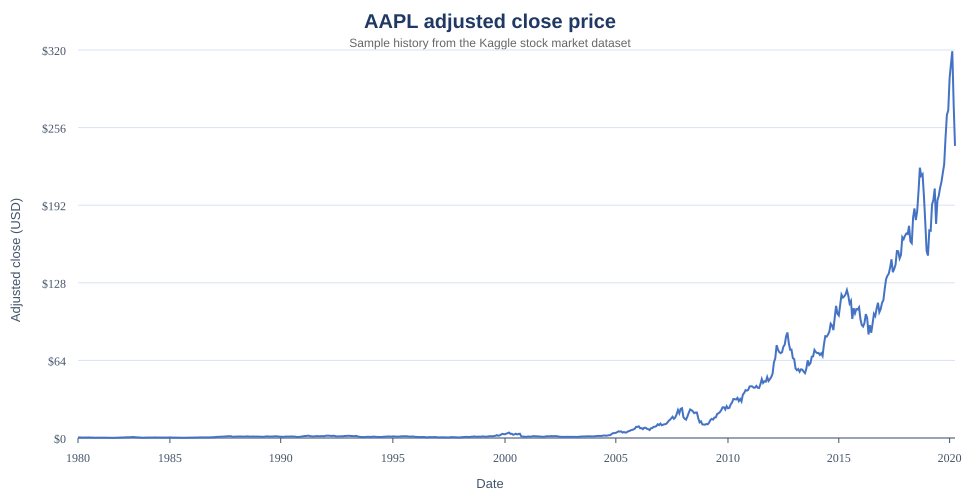

In [ ]:
# Saved AAPL chart preview from the dataset.
